# Naive Bayes with a False-Positive-Constrained Threshold

For this ad-blocking task, a false positive means real non-ad content is incorrectly blocked. We require a validation false-positive rate of no more than 5%, then maximize ad recall under that constraint.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline

In [3]:
candidates = [
    Path.cwd() / "ml" / "dataset" / "ad.data",
    Path.cwd() / "dataset" / "ad.data",
]
dataset_path = next((path for path in candidates if path.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Could not find ml/dataset/ad.data")

df = pd.read_csv(dataset_path, header=None, skipinitialspace=True, na_values="?")
df = df.drop_duplicates().reset_index(drop=True)

X = df.iloc[:, :-1]
y = df.iloc[:, -1].astype("string").str.strip().str.rstrip(".")

print(f"Dataset shape after duplicate removal: {df.shape}")
print("Class distribution:")
print(y.value_counts())

Dataset shape after duplicate removal: (2423, 1559)
Class distribution:
1558
nonad    2037
ad        386
Name: count, dtype: Int64


In [4]:
# Reserve 20% for final test evaluation.
X_fit, X_test, y_fit, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Use 25% of the remaining data as a threshold-validation set.
X_train, X_validation, y_train, y_validation = train_test_split(
    X_fit, y_fit, test_size=0.25, random_state=42, stratify=y_fit
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_validation))
print("Test rows:", len(X_test))

Training rows: 1453
Validation rows: 485
Test rows: 485


In [5]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", GaussianNB()),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U5](2,)","['ad','nonad']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1558
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note th

In [6]:
test_ad_probability = model.predict_proba(X_test)[:, ad_index]
y_test_binary = y_test.eq("ad").astype(int)
y_pred_binary = (test_ad_probability >= threshold).astype(int)

test_false_positive_count = ((y_pred_binary == 1) & (y_test_binary == 0)).sum()
test_non_ad_count = (y_test_binary == 0).sum()
test_false_positive_rate = test_false_positive_count / test_non_ad_count
test_precision = precision_score(y_test_binary, y_pred_binary, pos_label=1)
test_recall = recall_score(y_test_binary, y_pred_binary, pos_label=1)

print(f"False-positive limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
print(f"Test false positives: {test_false_positive_count} / {test_non_ad_count}")
print(f"Test false-positive rate: {test_false_positive_rate:.3%}")
print(f"Test ad precision: {test_precision:.4f}")
print(f"Test ad recall: {test_recall:.4f}")
print(f"Test F1 for ad: {f1_score(y_test_binary, y_pred_binary, pos_label=1):.4f}")
print(f"Test accuracy: {accuracy_score(y_test_binary, y_pred_binary):.4f}")

print("\nClassification report (ad = positive class):")
print(classification_report(y_test_binary, y_pred_binary, target_names=["nonad", "ad"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    y_pred_binary,
    display_labels=["nonad", "ad"],
)
plt.title(f"Naive Bayes Threshold {threshold:.3f}")
plt.tight_layout()
plt.show()

NameError: name 'ad_index' is not defined

In [ ]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.naive_bayes import BernoulliNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
MAX_FALSE_POSITIVE_RATE = 0.05
MIN_VALIDATION_RECALL = 0.50
CONTINUOUS_FEATURES = ["height", "width", "aratio"]


## 1. Load data and encode the target

Duplicates are removed (the EDA showed 856 duplicate rows) so the same rows do not appear in both train and test. The label is encoded as `ad=1`, `nonad=0` so that precision/recall treat the ad class as positive by default.


In [7]:
candidates = [
    Path.cwd() / "ml" / "dataset" / "ad.data",
    Path.cwd() / "dataset" / "ad.data",
]
dataset_path = next((p for p in candidates if p.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Could not find ad.data")

df = pd.read_csv(dataset_path, header=None, skipinitialspace=True, na_values="?")
df = df.drop_duplicates().reset_index(drop=True)

X = df.iloc[:, :-1].copy()
# Name columns: first three are continuous, the rest are 0/1 binary features.
X.columns = CONTINUOUS_FEATURES + [f"binary_{i}" for i in range(1, X.shape[1] - 2)]
y = (df.iloc[:, -1].astype("string").str.strip().str.rstrip(".")
     .map({"nonad": 0, "ad": 1}).astype("int8"))

print(f"Dataset shape after duplicate removal: {df.shape}")
print("Class distribution (ad=1, nonad=0):")
print(y.value_counts().sort_index())


Dataset shape after duplicate removal: (2423, 1559)
Class distribution (ad=1, nonad=0):
1558
0    2037
1     386
Name: count, dtype: int64


## 2. Leak-free train/validation/test split

The split is taken **before** any imputation or scaling so no statistics from the validation or test set leak into training. Sizes: 60% train / 20% validation / 20% test.


In [8]:
# Hold out the test set first (20%).
X_fit, X_test, y_fit, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
# From the remaining 80%, use 25% as a validation set -> 20% of the total.
X_train, X_validation, y_train, y_validation = train_test_split(
    X_fit, y_fit, test_size=0.25, random_state=RANDOM_STATE, stratify=y_fit
)

print(f"Training rows:   {len(X_train)}")
print(f"Validation rows: {len(X_validation)}")
print(f"Test rows:       {len(X_test)}")


Training rows:   1453
Validation rows: 485
Test rows:       485


## 3. Leak-free preprocessing inside a Pipeline

A `ColumnTransformer` applies different preprocessing to the two feature groups:

* **continuous** (height, width, aratio): `SimpleImputer(strategy="mean")` then `StandardScaler()` — these are the only columns scaled, per the brief. Scaling also centres them around zero so `BernoulliNB`'s `binarize` threshold splits each feature at its mean.
* **binary** (1555 columns): `SimpleImputer(strategy="most_frequent")` only, left unscaled.

The imputer and scaler live inside the pipeline, so they are fitted on the training fold only — even during cross-validation.


In [9]:
binary_features = [c for c in X.columns if c not in CONTINUOUS_FEATURES]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "continuous",
            Pipeline([
                ("imputer", SimpleImputer(strategy="mean")),
                ("scaler", StandardScaler()),
            ]),
            CONTINUOUS_FEATURES,
        ),
        (
            "binary",
            SimpleImputer(strategy="most_frequent"),
            binary_features,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)
preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('continuous', ...), ('binary', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transf

## 4. Baseline (DummyClassifier)

A stratified `DummyClassifier` makes random predictions respecting the class prior. It defines the floor a real model must beat. We report 5-fold stratified CV precision and recall as mean ± SD on the training data.


In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["precision", "recall"]

baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)),
])

baseline_cv = cross_validate(
    baseline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1,
)
print("Baseline — DummyClassifier (stratified), 5-fold CV (mean ± SD):")
print(f"  Precision (ad): {baseline_cv['test_precision'].mean():.4f} ± "
      f"{baseline_cv['test_precision'].std():.4f}")
print(f"  Recall    (ad): {baseline_cv['test_recall'].mean():.4f} ± "
      f"{baseline_cv['test_recall'].std():.4f}")


Baseline — DummyClassifier (stratified), 5-fold CV (mean ± SD):
  Precision (ad): 0.1347 ± 0.0666
  Recall    (ad): 0.1417 ± 0.0692


## 5. Bernoulli Naive Bayes — 5-fold CV with default hyperparameters

Before tuning, Naive Bayes is evaluated with 5-fold stratified CV on the training data, again reported as mean ± SD. `BernoulliNB` binarises each feature at 0.0 by default (after scaling, that means above/below the mean for the continuous columns).


In [11]:
nb_default = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BernoulliNB(binarize=0.0)),
])

nb_cv = cross_validate(
    nb_default, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1,
)
print("Bernoulli Naive Bayes (default) — 5-fold CV (mean ± SD):")
print(f"  Precision (ad): {nb_cv['test_precision'].mean():.4f} ± "
      f"{nb_cv['test_precision'].std():.4f}")
print(f"  Recall    (ad): {nb_cv['test_recall'].mean():.4f} ± "
      f"{nb_cv['test_recall'].std():.4f}")


Bernoulli Naive Bayes (default) — 5-fold CV (mean ± SD):
  Precision (ad): 0.9381 ± 0.0404
  Recall    (ad): 0.7069 ± 0.0775


## 6. Hyperparameter tuning with GridSearchCV

`GridSearchCV` searches over the Laplace smoothing `alpha` and the `binarize` threshold, using the same 5-fold stratified CV on the **training** data. The best estimator is then refit on the full training set (`refit=True`).


In [12]:
param_grid = {
    "classifier__alpha": [0.01, 0.1, 0.5, 1.0],
    "classifier__binarize": [0.0, 0.5],
}

grid = GridSearchCV(
    nb_default,
    param_grid,
    cv=cv,
    scoring=scoring,
    refit="precision",
    n_jobs=-1,
    return_train_score=False,
)

t0 = time.perf_counter()
grid.fit(X_train, y_train)
grid_time = time.perf_counter() - t0

print(f"Grid search over {len(grid.cv_results_['params'])} param combos "
      f"× {cv.get_n_splits()} folds (training time: {grid_time:.1f}s)")
print("Best parameters:", grid.best_params_)

best_idx = grid.best_index_
print(f"Best CV precision (mean ± SD): "
      f"{grid.cv_results_['mean_test_precision'][best_idx]:.4f} ± "
      f"{grid.cv_results_['std_test_precision'][best_idx]:.4f}")
print(f"Recall at that point     (mean ± SD): "
      f"{grid.cv_results_['mean_test_recall'][best_idx]:.4f} ± "
      f"{grid.cv_results_['std_test_recall'][best_idx]:.4f}")


Grid search over 8 param combos × 5 folds (training time: 5.4s)
Best parameters: {'classifier__alpha': 1.0, 'classifier__binarize': 0.5}
Best CV precision (mean ± SD): 0.9393 ± 0.0390
Recall at that point     (mean ± SD): 0.7155 ± 0.0724


## 7. Threshold selection on the validation set

The tuned model (already refit on the full training set) outputs probabilities. Following the chosen metric — **precision on the ad class**, since blocking real content is the worse mistake — we keep the validation false-positive rate **≤ 5%** and then **maximise precision**, subject to a recall floor of 0.50 so the threshold cannot collapse to predicting almost nothing as an ad. If no threshold meets the recall floor under the FPR cap, we fall back to the FPR-eligible threshold with the highest recall. This mirrors the threshold logic used in the Random Forest and SVM notebooks.


In [13]:
best_model = grid.best_estimator_
ad_index = list(best_model.classes_).index(1)

validation_ad_proba = best_model.predict_proba(X_validation)[:, ad_index]
nonad_count = int((y_validation == 0).sum())

candidate_thresholds = np.unique(np.concatenate((
    np.array([0.0]),
    validation_ad_proba,
)))

# Every threshold keeping the validation FPR under the stated limit.
fpr_eligible = []
for threshold in candidate_thresholds:
    predicted_ad = (validation_ad_proba >= threshold).astype(int)
    false_positives = int(((predicted_ad == 1) & (y_validation == 0)).sum())
    fpr = false_positives / nonad_count
    if fpr <= MAX_FALSE_POSITIVE_RATE:
        p = precision_score(y_validation, predicted_ad, zero_division=0)
        r = recall_score(y_validation, predicted_ad, zero_division=0)
        fpr_eligible.append((threshold, fpr, p, r))

if not fpr_eligible:
    raise RuntimeError("No threshold satisfies the validation false-positive limit")

# Prefer thresholds that also meet the recall floor; there, maximise precision.
eligible = [row for row in fpr_eligible if row[3] >= MIN_VALIDATION_RECALL]
if eligible:
    threshold, val_fpr, val_precision, val_recall = max(
        eligible, key=lambda row: (row[2], row[3], row[0])
    )
    print(f"Selected threshold: {threshold:.6f}")
    print(f"Validation false-positive-rate limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
    print(f"Validation false-positive rate: {val_fpr:.3%}")
    print(f"Validation ad precision: {val_precision:.4f}")
    print(f"Validation ad recall:    {val_recall:.4f}")
    print(f"Recall floor: {MIN_VALIDATION_RECALL:.2f} (met)")
else:
    # Fall back: keep the FPR guarantee, take the threshold with highest recall.
    threshold, val_fpr, val_precision, val_recall = max(
        fpr_eligible, key=lambda row: (row[3], row[2], row[0])
    )
    print(f"Selected threshold: {threshold:.6f}")
    print(f"Validation false-positive-rate limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
    print(f"Validation false-positive rate: {val_fpr:.3%}")
    print(f"Validation ad precision: {val_precision:.4f}")
    print(f"Validation ad recall:    {val_recall:.4f}")
    print(f"Warning: recall floor {MIN_VALIDATION_RECALL:.2f} not attainable under "
          f"the FPR cap; selected highest-recall FPR-eligible threshold.")


Selected threshold: 0.999812
Validation false-positive-rate limit: <= 5.0%
Validation false-positive rate: 0.245%
Validation ad precision: 0.9818
Validation ad recall:    0.7013
Recall floor: 0.50 (met)


## 8. Final evaluation on the held-out test set

The test set is used **once**, here, with the threshold chosen above.


False-positive limit: <= 5.0%
Test false positives: 1 / 408
Test false-positive rate: 0.245%
Test ad precision: 0.9800
Test ad recall:    0.6364
Test ad F1-score:  0.7717
Test accuracy:     0.9402

Classification report (ad = positive class):
              precision    recall  f1-score   support

       nonad       0.94      1.00      0.97       408
          ad       0.98      0.64      0.77        77

    accuracy                           0.94       485
   macro avg       0.96      0.82      0.87       485
weighted avg       0.94      0.94      0.93       485



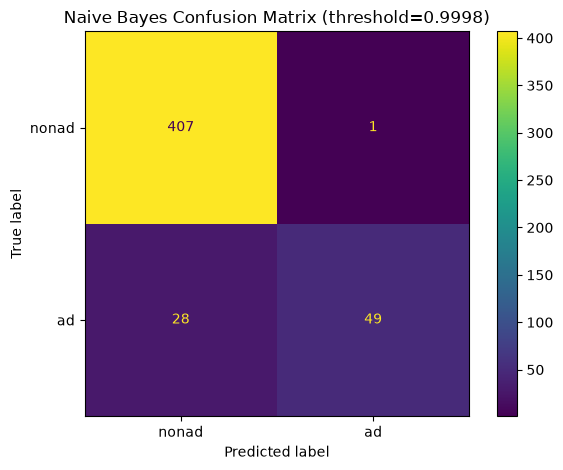

In [14]:
test_ad_proba = best_model.predict_proba(X_test)[:, ad_index]
y_pred = (test_ad_proba >= threshold).astype(int)

test_false_positives = int(((y_pred == 1) & (y_test == 0)).sum())
test_nonad_count = int((y_test == 0).sum())
test_fpr = test_false_positives / test_nonad_count

print(f"False-positive limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
print(f"Test false positives: {test_false_positives} / {test_nonad_count}")
print(f"Test false-positive rate: {test_fpr:.3%}")
print(f"Test ad precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Test ad recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Test ad F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Test accuracy:     {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification report (ad = positive class):")
print(classification_report(y_test, y_pred, target_names=["nonad", "ad"],
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["nonad", "ad"],
)
plt.title(f"Naive Bayes Confusion Matrix (threshold={threshold:.4f})")
plt.tight_layout()
plt.show()


In [ ]:
## 9. Feature importance — Naive Bayes log-likelihood ratios

`BernoulliNB` does not have a `feature_importances_` attribute; its per-feature coefficients are the class-conditional log-probabilities `feature_log_prob_`. The quantity that tells us how strongly a feature pushes toward the ad class is the log-likelihood ratio

$$\log \frac{P(x_j=1 \mid ad)}{P(x_j=1 \mid nonad)} = \log P(x_j=1 \mid ad) - \log P(x_j=1 \mid nonad).$$

A large positive value means the feature is far more common in ads; a large negative value means it is far more common in non-ads. We display the strongest features in each direction, mapped to their real names from `ad.names`.


Top 15 features pushing toward ad:


,log-likelihood ratio
ancurl*http+www,5.437931
ancurl*familyid,4.949578
ancurl*tagvalues,4.949578
ancurl*groupid,4.949578
ancurl*groupid+1,4.698263
ancurl*1+familyid,4.698263
ancurl*cid,4.598180
ancurl*url,4.544113
ancurl*adclick,4.544113
url*ads+media,4.544113


Top 15 features pushing toward nonad:


,log-likelihood ratio
url*images+geoguideii,-3.064758
url*geoguideii,-3.064758
url*b+gif,-2.752978
ancurl*ring,-2.316551
ancurl*www.webring.org,-2.278085
ancurl*webring.org,-2.278085
ancurl*webring,-2.278085
ancurl*bin+webring,-2.258282
origurl*aol.com,-2.217460
url*tkaine,-2.196407


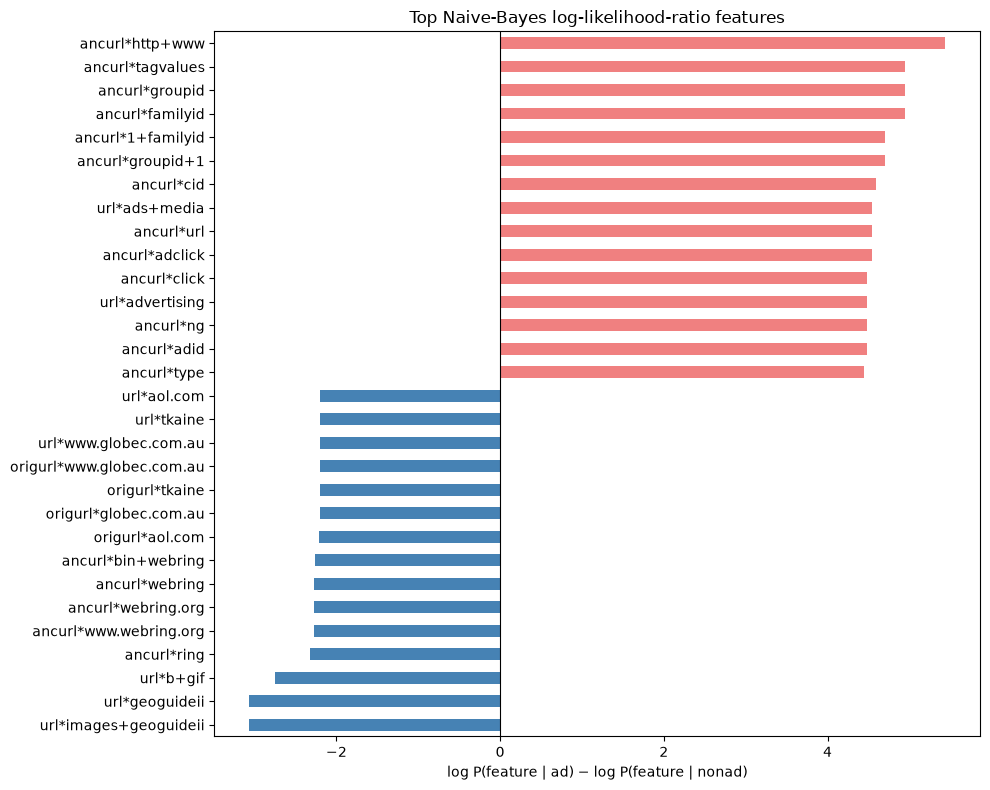

In [15]:
nb_clf = best_model.named_steps["classifier"]
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

ad_pos = list(nb_clf.classes_).index(1)
nonad_pos = list(nb_clf.classes_).index(0)
log_lr = nb_clf.feature_log_prob_[ad_pos] - nb_clf.feature_log_prob_[nonad_pos]
lr = pd.Series(log_lr, index=feature_names)

# Map the generic binary_N labels to the real token names listed in ad.names
# (the same parsing used in the EDA notebook), so the interpretation is verifiable.
import re
display_names = {c: c for c in lr.index}
for p in [Path.cwd() / "ml" / "dataset" / "ad.names",
          Path.cwd() / "dataset" / "ad.names"]:
    if p.exists():
        attr = []
        for line in p.read_text(encoding="latin-1").splitlines():
            m = re.match(r"^\s*(.+?):\s*(?:continuous|0,1)\.", line)
            if m:
                attr.append(m.group(1).strip())
        if len(attr) == X.shape[1]:
            display_names = {
                X.columns[j]: (X.columns[j] if X.columns[j] in CONTINUOUS_FEATURES
                               else attr[j])
                for j in range(X.shape[1])
            }
        break
lr.index = [display_names.get(c, c) for c in lr.index]

print("Top 15 features pushing toward ad:")
display(lr.sort_values(ascending=False).head(15).to_frame("log-likelihood ratio"))
print("Top 15 features pushing toward nonad:")
display(lr.sort_values(ascending=True).head(15).to_frame("log-likelihood ratio"))

top_features = pd.concat([
    lr.sort_values(ascending=False).head(15),
    lr.sort_values(ascending=True).head(15),
]).sort_values()
plt.figure(figsize=(10, 8))
top_features.plot(kind="barh", color=["steelblue"] * 15 + ["lightcoral"] * 15)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("log P(feature | ad) − log P(feature | nonad)")
plt.title("Top Naive-Bayes log-likelihood-ratio features")
plt.tight_layout()
plt.show()


## 10. Interpretation and limitations

**Interpretation.** Naive Bayes treats each feature as an independent signal of the
class (the "naive" independence assumption). The features with the largest positive
log-likelihood ratios — far more common in ads than in non-ads — are anchor-URL
tokens such as `ancurl*http+www`, `ancurl*familyid`, `ancurl*tagvalues`,
`ancurl*groupid`, `ancurl*cid`, `ancurl*adclick`, `ancurl*click` and
`ancurl*adid`, plus URL tokens such as `url*ads+media` and `url*advertising` —
exactly the click-through, ad-ID and ad-server patterns an ad blocker would expect;
image geometry (`width`, `aratio`) also contributes. The largest negative ratios
are tokens that *rule out* an ad — tied to 1990s personal-page and web-ring content
(`url*geoguideii`, `ancurl*webring`, `url*aol.com`, `origurl*globec.com.au`), i.e.
ordinary non-ad pages. Because the model is linear in log-space and assumes feature
independence, each present feature simply adds its log-likelihood ratio to the
ad-vs-nonad log-odds, so these effects are directly interpretable.

**What this model cannot be trusted to do.**

* **The independence assumption is wrong for this data.** URL, alt-text and anchor
  tokens co-occur (the same ad network sets many at once), so the features are
  strongly correlated. Naive Bayes double-counts correlated evidence, which is why
  its probabilities are over-confident (the chosen threshold is ~0.9998, far from
  0.5) and why a tuned threshold rather than the raw cut-off is needed.
* **It will not transfer to today's web.** The data is from 1998: ads were static
  banners with predictable sizes and ad-network URLs. Modern ads are served
  programmatically, are often indistinguishable from content (native ads), are
  injected client-side by scripts, and live behind CDNs whose URLs and tokens
  differ entirely from 1998 ad networks. The token vocabulary here simply does not
  exist on the modern web, so the model should not be trusted on today's pages
  without retraining on current data.
* **Continuous features are binarised.** `BernoulliNB` can only use whether a
  feature is present/absent; the scaled height/width/aratio are reduced to
  above/below a threshold, throwing away the magnitude information that a model
  like Random Forest uses.
* **The operating point is fragile.** The precision-focused threshold and its 5%
  false-positive cap were chosen on a small validation split (485 rows); on a
  different population the achieved false-positive rate can drift, so the threshold
  should be re-validated before deployment.
